Shape of X: (10, 2)
[[0.37454012 0.95071431]
 [0.73199394 0.59865848]
 [0.15601864 0.15599452]
 [0.05808361 0.86617615]
 [0.60111501 0.70807258]
 [0.02058449 0.96990985]
 [0.83244264 0.21233911]
 [0.18182497 0.18340451]
 [0.30424224 0.52475643]
 [0.43194502 0.29122914]]


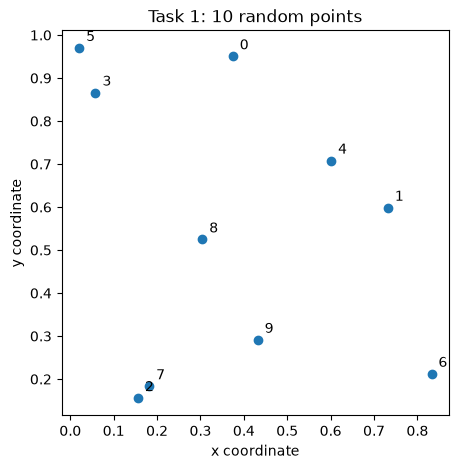

In [2]:
# Task 1: Data Generation 
import numpy as np
import matplotlib.pyplot as plt

# Fixed seed so the "random" numbers are the same every run
rng = np.random.RandomState(42)
X = rng.rand(10, 2)          # 10 points, each with an (x, y) coordinate
print("Shape of X:", X.shape)
print(X)

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], color="tab:blue")
for i, (x, y) in enumerate(X):          # label each point with its index (plotting only)
    plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(5, 5))
plt.title("Task 1: 10 random points")
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.show()

In [3]:
# Task 2:Pairwise Squared Distances
# --- One-line version ---
dist_sq = np.sum((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2, axis=-1)
print("One-line result shape:", dist_sq.shape)

# --- Same thing in three steps, printing each shape ---
diff = X[:, np.newaxis, :] - X[np.newaxis, :, :]   # (a) coordinate differences
print("(a) differences shape:        ", diff.shape)      # (10, 10, 2)

sq_diff = diff ** 2                                  # (b) squared differences
print("(b) squared differences shape:", sq_diff.shape)   # (10, 10, 2)

dist_sq_3 = sq_diff.sum(axis=-1)                     # (c) sum over the x,y axis
print("(c) summed distances shape:   ", dist_sq_3.shape) # (10, 10)

print("Both methods agree:", np.allclose(dist_sq, dist_sq_3))

One-line result shape: (10, 10)
(a) differences shape:         (10, 10, 2)
(b) squared differences shape: (10, 10, 2)
(c) summed distances shape:    (10, 10)
Both methods agree: True


In [4]:
#Task 3:Verification:The diagonal is zero
print("Diagonal:", np.diag(dist_sq))
print("All zeros?", np.all(np.diag(dist_sq) == 0))

Diagonal: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
All zeros? True


In [6]:
#Task 4:sorting for neighbors
#4a): np.argsort  along axis=1
nearest = np.argsort(dist_sq, axis=1)   # each row: point indices from closest to farthest
print(nearest)
print("First column:", nearest[:, 0])
#4b):np.argpartition for  k=2
K = 2
# Move the K+1 smallest distances (self + K neighbors) to the front of each row.
# They are NOT fully sorted among themselves.
part = np.argpartition(dist_sq, K + 1, axis=1)[:, :K + 1]
print("K+1 smallest per row (unordered):\n", part)

# Sort just those K+1 candidates so we can read off neighbors in order
rows = np.arange(X.shape[0])[:, np.newaxis]
order = np.argsort(dist_sq[rows, part], axis=1)
part_sorted = part[rows, order]
print("\nSorted K+1:\n", part_sorted)

# Check against full argsort (first K+1 columns)
print("\nMatches full sort:", np.array_equal(part_sorted, nearest[:, :K + 1]))

[[0 3 4 5 8 1 9 7 2 6]
 [1 4 6 9 8 0 7 3 2 5]
 [2 7 9 8 6 4 3 1 0 5]
 [3 5 0 8 4 9 7 2 1 6]
 [4 1 0 8 9 6 3 5 7 2]
 [5 3 0 8 4 9 1 7 2 6]
 [6 1 9 4 8 7 2 0 3 5]
 [7 2 9 8 6 4 1 3 0 5]
 [8 9 4 7 2 3 0 1 5 6]
 [9 8 7 2 6 1 4 0 3 5]]
First column: [0 1 2 3 4 5 6 7 8 9]
K+1 smallest per row (unordered):
 [[0 3 4]
 [1 4 6]
 [2 7 9]
 [3 5 0]
 [4 1 0]
 [5 3 0]
 [6 1 9]
 [7 2 9]
 [8 9 4]
 [9 8 7]]

Sorted K+1:
 [[0 3 4]
 [1 4 6]
 [2 7 9]
 [3 5 0]
 [4 1 0]
 [5 3 0]
 [6 1 9]
 [7 2 9]
 [8 9 4]
 [9 8 7]]

Matches full sort: True


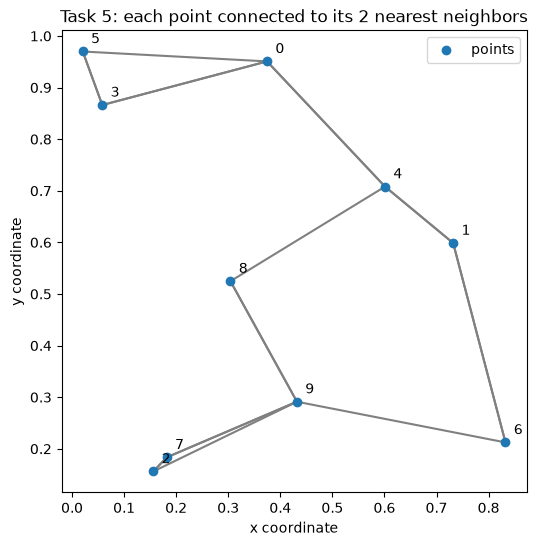

Times each point is chosen as a neighbor: [3 2 1 2 3 1 1 2 1 4]


In [7]:
#Task 5:Visualization of neighbor network
neighbors = part_sorted[:, 1:]          # drop column 0 (the point itself)

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], color="tab:blue", zorder=3, label="points")
for i in range(X.shape[0]):
    plt.annotate(str(i), X[i], textcoords="offset points", xytext=(6, 6))
    for j in neighbors[i]:              # (plot-drawing loop only; not used for distances)
        plt.plot([X[i, 0], X[j, 0]], [X[i, 1], X[j, 1]], color="gray", zorder=1)
plt.title("Task 5: each point connected to its 2 nearest neighbors")
plt.xlabel("x coordinate")
plt.ylabel("y coordinate")
plt.legend()
plt.show()

# Count how many times each point is chosen as someone's neighbor
counts = np.bincount(neighbors.ravel(), minlength=X.shape[0])
print("Times each point is chosen as a neighbor:", counts)

Same result: True
2.83 ms ± 128 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)
764 μs ± 50.3 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)
94.4 ms ± 3.18 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)
93.8 ms ± 3.27 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)
2.11 s ± 18.8 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)
2.64 s ± 297 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


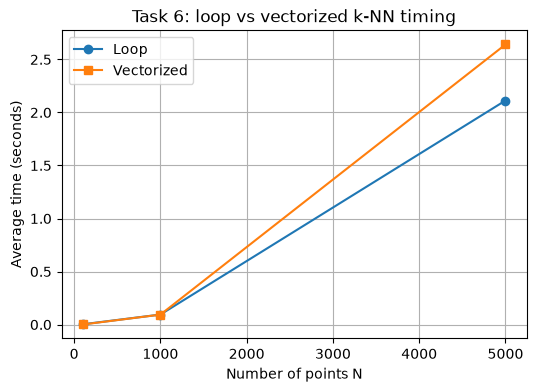

In [10]:
#Task 6: Performance comparison
#6a):loop-based version and vectorized version as functions
def knn_loop(X):
    """Loop version: handle one point at a time."""
    n = X.shape[0]
    result = np.empty((n, n), dtype=int)
    for i in range(n):
        d = np.sum((X - X[i]) ** 2, axis=1)   # distances from point i to all points
        result[i] = np.argsort(d)              # sort them
    return result

def knn_vectorized(X):
    """Vectorized version: everything at once with broadcasting."""
    d = np.sum((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2, axis=-1)
    return np.argsort(d, axis=1)

# Sanity check: both give the same answer
print("Same result:", np.array_equal(knn_loop(X), knn_vectorized(X)))
#6b):Timing with %timeit
import pandas as pd
sizes = [100, 1000, 5000]
loop_times, vec_times = [], []

for n in sizes:
    Xn = np.random.RandomState(0).rand(n, 2)
    # -o stores the result so we can put it in a table; fewer runs for big N
    kw = "-n 10 -r 3" if n == 100 else "-n 1 -r 3"
    t_loop = get_ipython().run_line_magic("timeit", f"{kw} -o knn_loop(Xn)")
    t_vec  = get_ipython().run_line_magic("timeit", f"{kw} -o knn_vectorized(Xn)")
    loop_times.append(t_loop.average)
    vec_times.append(t_vec.average)

table = pd.DataFrame({
    "N": sizes,
    "Loop (s)": loop_times,
    "Vectorized (s)": vec_times,
})
table["Speed-up (loop / vectorized)"] = table["Loop (s)"] / table["Vectorized (s)"]
table.round(4)
plt.figure(figsize=(6, 4))
plt.plot(sizes, loop_times, "o-", label="Loop")
plt.plot(sizes, vec_times, "s-", label="Vectorized")
plt.xlabel("Number of points N")
plt.ylabel("Average time (seconds)")
plt.title("Task 6: loop vs vectorized k-NN timing")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
#Bonus:Tree-based method (KD-tree from  scikit-learn)
from sklearn.neighbors import KDTree
import time

N = 1000
Xb = np.random.RandomState(1).rand(N, 2)
K = 2

# NumPy brute force
t0 = time.perf_counter()
d = np.sum((Xb[:, np.newaxis, :] - Xb[np.newaxis, :, :]) ** 2, axis=-1)
idx_numpy = np.argsort(d, axis=1)[:, :K + 1]
t_numpy = time.perf_counter() - t0

# KD-Tree (build + query)
t0 = time.perf_counter()
tree = KDTree(Xb)
_, idx_tree = tree.query(Xb, k=K + 1)
t_tree = time.perf_counter() - t0

print(f"NumPy brute force: {t_numpy:.4f} s")
print(f"KDTree (build+query): {t_tree:.4f} s")
print("Same neighbors:", np.array_equal(idx_numpy, idx_tree))

NumPy brute force: 0.0869 s
KDTree (build+query): 0.0038 s
Same neighbors: True
